# Bank Customer Balance Analysis – Sample Data Analyst Project
**Audience:** B.Tech 1st Year students (Data Analyst track) | **Tools:** Python, pandas, matplotlib, seaborn

## 1. Business problem
A retail bank's customer-relations team wants to understand **what drives customers' average monthly balance** so that relationship managers can support customers drifting toward low balances early.

**Questions we will answer**
1. What does the average monthly balance look like overall?
2. Do monthly income and tenure affect the balance?
3. Does the balance differ by account type, city, employment type or preferred channel?
4. Which customers need attention (average monthly balance below ₹30,000)?

> The dataset is **synthetic** (computer-generated) and contains no real customer data.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
sns.set_theme(style='whitegrid')
plt.rcParams['figure.dpi']=100

In [3]:
df = pd.read_csv('bank.csv.csv')
print('Rows, Columns:', df.shape)
df.head()

Rows, Columns: (255, 11)


,Customer_ID,City,Account_Type,Employment_Type,Preferred_Channel,Age,Tenure_Years,Monthly_Income_INR,Monthly_Transactions,Last_Transaction_Date,Avg_Monthly_Balance_INR
0,C1150,Lucknow,Premium,Student,Mobile App,45,1.9,37000.0,31,2026-04-06,26620
1,C1123,Mumbai,Savings,Salaried,Mobile App,23,8.7,32500.0,15,2026-05-02,27290
2,C1015,Lucknow,Premium,Salaried,Net Banking,46,9.7,33500.0,20,2026-08-12,102930
3,C1139,Bengaluru,Salary,Self-Employed,Mobile App,44,3.4,40000.0,14,2026-07-29,53180
4,C1159,Bengaluru,Current,Self-Employed,Branch,40,NaN,32500.0,8,2026-01-15,73110


In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 255 entries, 0 to 254
Data columns (total 11 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   Customer_ID              255 non-null    object 
 1   City                     255 non-null    object 
 2   Account_Type             255 non-null    object 
 3   Employment_Type          251 non-null    object 
 4   Preferred_Channel        255 non-null    object 
 5   Age                      255 non-null    int64  
 6   Tenure_Years             249 non-null    float64
 7   Monthly_Income_INR       250 non-null    float64
 8   Monthly_Transactions     255 non-null    int64  
 9   Last_Transaction_Date    250 non-null    object 
 10  Avg_Monthly_Balance_INR  255 non-null    int64  
dtypes: float64(2), int64(3), object(6)
memory usage: 22.0+ KB


In [5]:
print('Missing values per column:'); print(df.isna().sum()[df.isna().sum()>0])
print('\nDuplicate rows:', df.duplicated().sum())
df.describe().round(1)

Missing values per column:
Employment_Type          4
Tenure_Years             6
Monthly_Income_INR       5
Last_Transaction_Date    5
dtype: int64

Duplicate rows: 5


,Age,Tenure_Years,Monthly_Income_INR,Monthly_Transactions,Avg_Monthly_Balance_INR
count,255.0,249.0,250.0,255.0,255.0
mean,39.8,7.2,50322.0,27.4,64732.1
std,15.7,4.4,22972.6,10.4,37082.3
min,-24.0,0.8,12000.0,3.0,1500.0
25%,31.0,4.0,33500.0,20.0,36055.0
50%,39.0,6.3,46250.0,28.0,62380.0
75%,46.0,9.4,62000.0,34.0,88600.0
max,212.0,20.0,129500.0,58.0,171750.0


In [7]:
clean = df.copy()
# 1. Remove duplicate rows
clean = clean.drop_duplicates()
# 2. Standardise text
clean['City'] = clean['City'].str.strip().str.title()
# 3. Fix impossible values (age must be between 18 and 75)
clean.loc[(clean['Age']<18)|(clean['Age']>75),'Age'] = np.nan
# 4. Fill missing numbers with the median (robust to outliers)
num_cols = ['Age','Tenure_Years','Monthly_Income_INR','Monthly_Transactions']
for c in num_cols:
    clean[c] = clean[c].fillna(clean[c].median())
clean[['Age','Monthly_Income_INR']] = clean[['Age','Monthly_Income_INR']].round().astype(int)
# 5. Fill missing category with the most common value and fix the date column
clean['Employment_Type'] = clean['Employment_Type'].fillna(clean['Employment_Type'].mode()[0])
clean['Last_Transaction_Date'] = pd.to_datetime(clean['Last_Transaction_Date'])
clean['Last_Transaction_Date'] = clean['Last_Transaction_Date'].fillna(clean['Last_Transaction_Date'].median())
print('Rows after cleaning:', len(clean), '| Missing values left:', clean.isna().sum().sum())

Rows after cleaning: 250 | Missing values left: 0


In [8]:
clean['Balance_to_Income_Ratio'] = (clean['Avg_Monthly_Balance_INR']/clean['Monthly_Income_INR']).round(2)
def segment(b):
    if b>=100000: return 'High Value'
    if b>=30000: return 'Healthy'
    return 'Low Balance'
clean['Customer_Segment'] = clean['Avg_Monthly_Balance_INR'].apply(segment)
clean['Age_Group'] = pd.cut(clean['Age'],[17,25,35,50,75],labels=['18-25','26-35','36-50','51-75'])
clean[['Customer_ID','Balance_to_Income_Ratio','Customer_Segment','Age_Group']].head()

,Customer_ID,Balance_to_Income_Ratio,Customer_Segment,Age_Group
0,C1150,0.72,Low Balance,36-50
1,C1123,0.84,Low Balance,18-25
2,C1015,3.07,High Value,36-50
3,C1139,1.33,Healthy,36-50
4,C1159,2.25,Healthy,36-50


count       250.0
mean      63921.7
std       36425.1
min        1500.0
25%       35922.5
50%       61835.0
75%       88150.0
max      171750.0
Name: Avg_Monthly_Balance_INR, dtype: float64


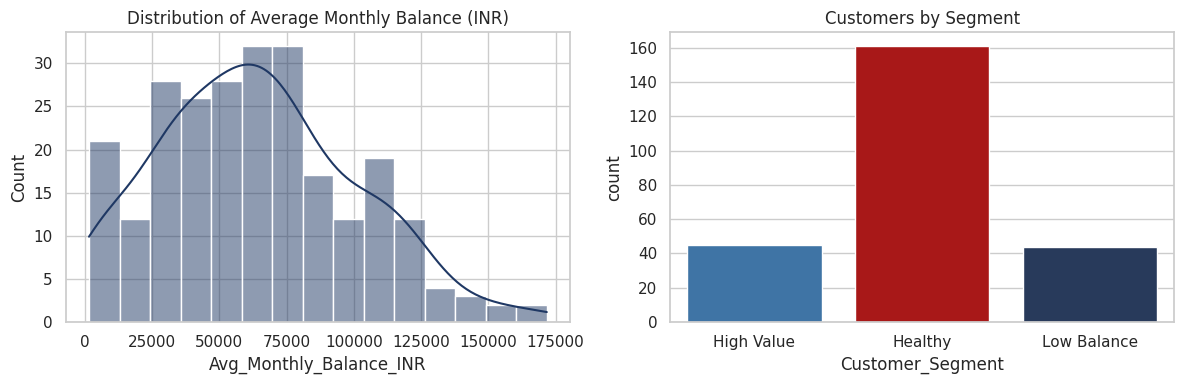

In [28]:
print(clean['Avg_Monthly_Balance_INR'].describe().round(1))
fig,ax=plt.subplots(1,2,figsize=(12,4))
sns.histplot(clean['Avg_Monthly_Balance_INR'],bins=15,kde=True,color='#1F3864',ax=ax[0]);ax[0].set_title('Distribution of Average Monthly Balance (INR)')
order=['High Value','Healthy','Low Balance']
sns.countplot(data=clean,x='Customer_Segment',hue='Customer_Segment',legend=False,order=order,palette=['#1F3864','#2E75B6','#C00000'],ax=ax[1]);ax[1].set_title('Customers by Segment')
plt.tight_layout();plt.show()

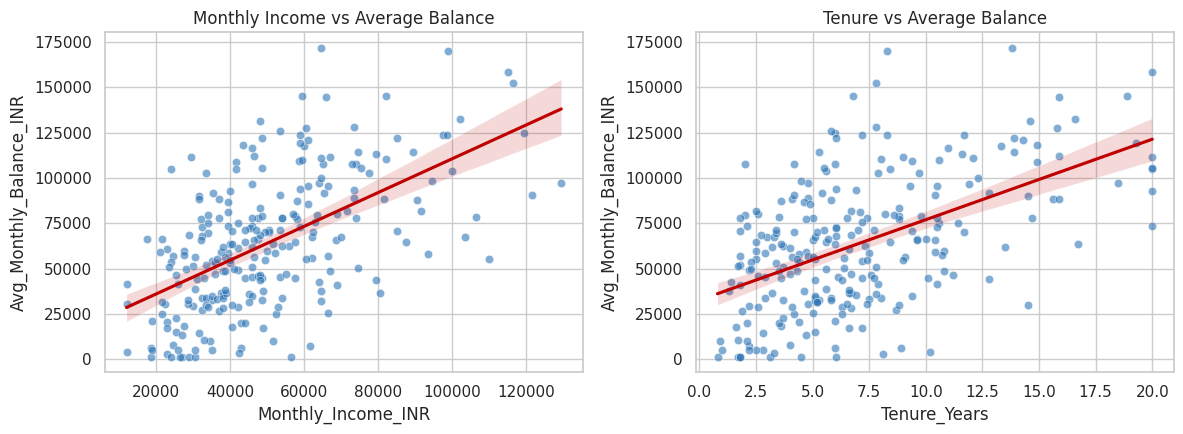

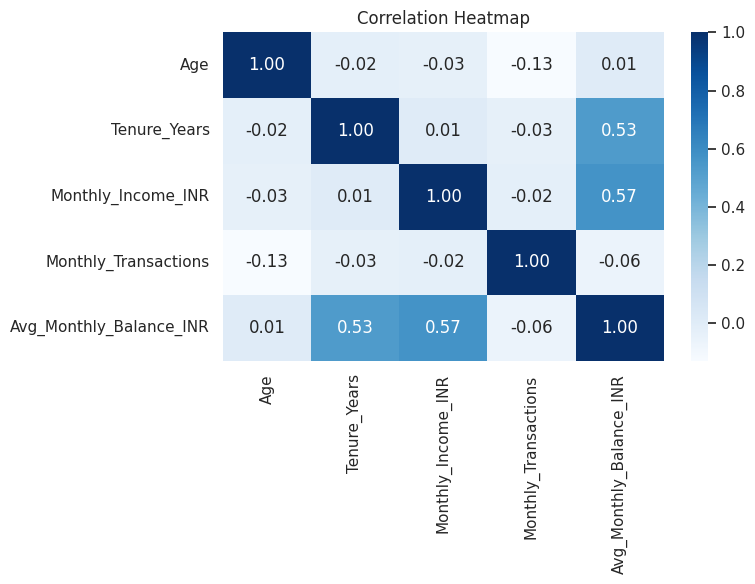

In [29]:
fig,ax=plt.subplots(1,2,figsize=(12,4.5))
sns.scatterplot(data=clean,x='Monthly_Income_INR',y='Avg_Monthly_Balance_INR',alpha=.6,color='#2E75B6',ax=ax[0])
sns.regplot(data=clean,x='Monthly_Income_INR',y='Avg_Monthly_Balance_INR',scatter=False,color='#C00000',ax=ax[0]);ax[0].set_title('Monthly Income vs Average Balance')
sns.scatterplot(data=clean,x='Tenure_Years',y='Avg_Monthly_Balance_INR',alpha=.6,color='#2E75B6',ax=ax[1])
sns.regplot(data=clean,x='Tenure_Years',y='Avg_Monthly_Balance_INR',scatter=False,color='#C00000',ax=ax[1]);ax[1].set_title('Tenure vs Average Balance')
plt.tight_layout();#plt.savefig('../images/02_income_tenure.png');plt.show()
plt.figure(figsize=(8,6))
sns.heatmap(clean[num_cols+['Avg_Monthly_Balance_INR']].corr().round(2),annot=True,cmap='Blues',fmt='.2f');plt.title('Correlation Heatmap')
plt.tight_layout();#plt.savefig('../images/03_correlation.png');plt.show()

In [12]:
print(clean.groupby('Age_Group',observed=True)['Avg_Monthly_Balance_INR'].agg(['count','mean']).round(1))

           count     mean
Age_Group                
18-25         25  65025.6
26-35         67  56990.7
36-50        122  68147.9
51-75         36  61732.2


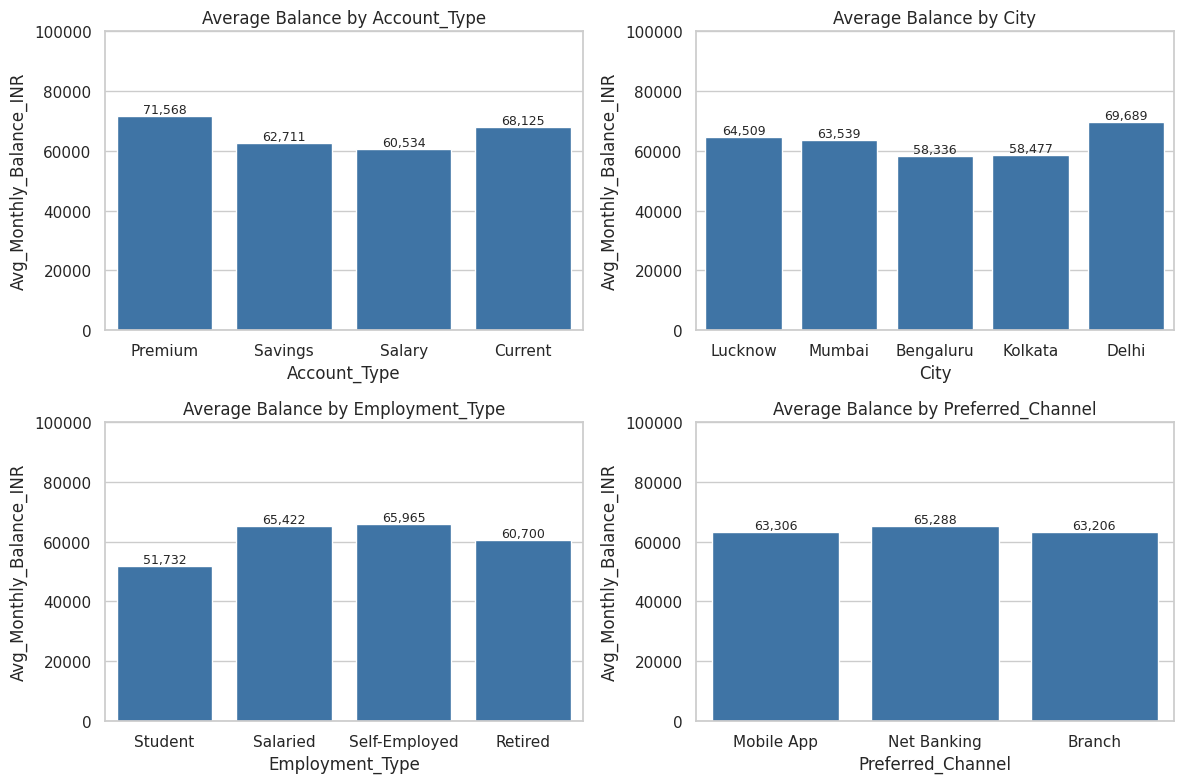

In [30]:
fig,ax=plt.subplots(2,2,figsize=(12,8))
for a,col in zip(ax.flat,['Account_Type','City','Employment_Type','Preferred_Channel']):
    sns.barplot(data=clean,x=col,y='Avg_Monthly_Balance_INR',errorbar=None,color='#2E75B6',ax=a)
    a.set_title(f'Average Balance by {col}');a.set_ylim(0,100000)
    for p in a.patches:a.annotate(f'{p.get_height():,.0f}',(p.get_x()+p.get_width()/2,p.get_height()),ha='center',va='bottom',fontsize=9)
plt.tight_layout();#plt.savefig('../images/04_group_comparison.png');plt.show()

In [14]:
risk = clean[clean['Customer_Segment']=='Low Balance'].sort_values('Avg_Monthly_Balance_INR')
print(f'{len(risk)} customers ({len(risk)/len(clean):.1%}) have a Low Balance')
print('Average income of Low Balance customers: Rs', round(risk['Monthly_Income_INR'].mean()),'vs overall Rs', round(clean['Monthly_Income_INR'].mean()))
print('Average tenure of Low Balance customers:', round(risk['Tenure_Years'].mean(),1),'years vs overall', round(clean['Tenure_Years'].mean(),1),'years')
risk[['Customer_ID','City','Account_Type','Monthly_Income_INR','Tenure_Years','Avg_Monthly_Balance_INR']].head(10)

44 customers (17.6%) have a Low Balance
Average income of Low Balance customers: Rs 33920 vs overall Rs 49966
Average tenure of Low Balance customers: 4.2 years vs overall 7.1 years


,Customer_ID,City,Account_Type,Monthly_Income_INR,Tenure_Years,Avg_Monthly_Balance_INR
10,C1188,Lucknow,Current,18500,4.50,1500
69,C1172,Bengaluru,Savings,56500,1.80,1500
41,C1046,Delhi,Salary,26500,6.05,1500
37,C1243,Mumbai,Salary,27000,1.70,1500
102,C1163,Delhi,Salary,29000,0.80,1500
110,C1111,Mumbai,Salary,30500,3.10,1500
178,C1204,Lucknow,Premium,24000,1.80,1500
140,C1104,Mumbai,Savings,23000,8.10,2630
161,C1162,Delhi,Savings,42500,3.30,3510
122,C1101,Bengaluru,Salary,12000,10.20,4040


In [15]:
r_inc=clean['Monthly_Income_INR'].corr(clean['Avg_Monthly_Balance_INR']);r_ten=clean['Tenure_Years'].corr(clean['Avg_Monthly_Balance_INR'])
best=clean.groupby('Account_Type')['Avg_Monthly_Balance_INR'].mean().idxmax();worst=clean.groupby('Account_Type')['Avg_Monthly_Balance_INR'].mean().idxmin()
acc=clean.groupby('Account_Type')['Avg_Monthly_Balance_INR'].mean()
print(f"1. Average monthly balance: Rs {clean['Avg_Monthly_Balance_INR'].mean():,.0f}; median Rs {clean['Avg_Monthly_Balance_INR'].median():,.0f}.")
print(f"2. Income vs balance correlation = {r_inc:.2f}; tenure vs balance = {r_ten:.2f} (both positive).")
print(f"3. Highest-balance account type: {best}; lowest: {worst}.")
print(f"4. Premium accounts average Rs {acc['Premium']:,.0f} vs Rs {acc['Savings']:,.0f} for Savings accounts.")
print(f"5. {len(risk)} customers have a Low Balance; their average income is Rs {risk['Monthly_Income_INR'].mean():,.0f}.")

1. Average monthly balance: Rs 63,922; median Rs 61,835.
2. Income vs balance correlation = 0.57; tenure vs balance = 0.53 (both positive).
3. Highest-balance account type: Premium; lowest: Salary.
4. Premium accounts average Rs 71,568 vs Rs 62,711 for Savings accounts.
5. 44 customers have a Low Balance; their average income is Rs 33,920.


In [17]:
clean.to_csv('bank.csv.csv',index=False)
print('Saved cleaned file with', len(clean), 'rows')

Saved cleaned file with 250 rows
